# Parte 2 — Cutoff de decisión con criterio económico

**Objetivo:** definir a partir de qué PD conviene rechazar una solicitud, por mercado,
y medir cuánto cuesta (en ganancia) cumplir con las restricciones de fairness.

**Idea central.** Con una PD *calibrada*, la ganancia esperada de prestar una unidad a un período es

$$E[\text{ganancia}] = (1 - PD)\cdot r - PD \cdot LGD$$

Se anula en **PD\* = r / (r + LGD)**: conviene aprobar a todos los que tienen PD menor a ese valor.
Este cutoff analítico se contrasta con el óptimo empírico sobre el test set.

> **Nota sobre la versión anterior de esta notebook.** El análisis original buscaba el óptimo
> en `np.arange(0.15, 0.75, 0.025)` sobre el score **sin calibrar**. Los cuatro mercados
> daban 0,725, que es justo el último valor de la grilla: el óptimo estaba fuera del rango
> buscado y el resultado era un artefacto, no una propiedad del modelo.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import load_policy, breakeven_pd
from src.models.pd_model import PDScorer
from src.validation.model_validation import age_groups

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

scorer   = PDScorer()
X_test   = pd.read_parquet('data/processed/X_test.parquet')
y_test   = pd.read_parquet('data/processed/y_test.parquet').iloc[:, 0].values
raw_test = pd.read_parquet('data/processed/test.parquet')

raw_score = scorer.raw_score(X_test)
pd_test   = scorer.calibrator.transform(raw_score)
gender    = raw_test['CODE_GENDER'].values
age_g     = age_groups(raw_test['age_years']).values

print(f'Default real:        {y_test.mean():.2%}')
print(f'Score crudo (media): {raw_score.mean():.2%}   <- no es una PD')
print(f'PD calibrada (media):{pd_test.mean():.2%}')

Default real:        8.07%
Score crudo (media): 38.82%   <- no es una PD
PD calibrada (media):7.94%


## 2.1 Supuestos por mercado

Los parámetros están en `configs/credit_policy.json` (con su fuente). Son supuestos de un
ejercicio: TEA nominal y LGD estimada, sin costo de fondeo ni costos operativos.

In [2]:
policy = load_policy()
mercados = pd.DataFrame(policy['mercados']).T[['tasa_interes_anual', 'lgd']].astype(float)
mercados['pd_breakeven'] = [breakeven_pd(r, l) for r, l in zip(mercados['tasa_interes_anual'], mercados['lgd'])]
mercados.style.format({'tasa_interes_anual': '{:.1%}', 'lgd': '{:.0%}', 'pd_breakeven': '{:.1%}'})

,tasa_interes_anual,lgd,pd_breakeven
Argentina,80.0%,68%,54.1%
USA,11.5%,45%,20.4%
Brasil,59.0%,60%,49.6%
Colombia,26.8%,55%,32.7%


## 2.2 Curvas de ganancia y fairness por cutoff

Para cada cutoff se calculan, sobre el test set:
- la ganancia por unidad prestada (promedio sobre todas las solicitudes);
- la tasa de aprobación y el default entre los aprobados;
- el Disparate Impact Ratio por género y por edad.

In [3]:
def dir_ratio(approved, group):
    rates = pd.Series(approved).groupby(group).mean()
    return rates.min() / rates.max()

mask_g = np.isin(gender, ['M', 'F'])
cutoffs = np.round(np.arange(0.01, 0.80, 0.005), 3)

def curva(score, r, lgd):
    rows = []
    for c in cutoffs:
        ap = score < c
        rows.append({
            'cutoff': c,
            'ganancia': (ap * ((1 - y_test) * r - y_test * lgd)).mean(),
            'aprobacion': ap.mean(),
            'mora_aprobados': y_test[ap].mean() if ap.any() else np.nan,
            'dir_genero': dir_ratio(ap[mask_g], gender[mask_g]),
            'dir_edad': dir_ratio(ap, age_g),
        })
    return pd.DataFrame(rows)

curvas = {m: curva(pd_test, p['tasa_interes_anual'], p['lgd']) for m, p in mercados.iterrows()}

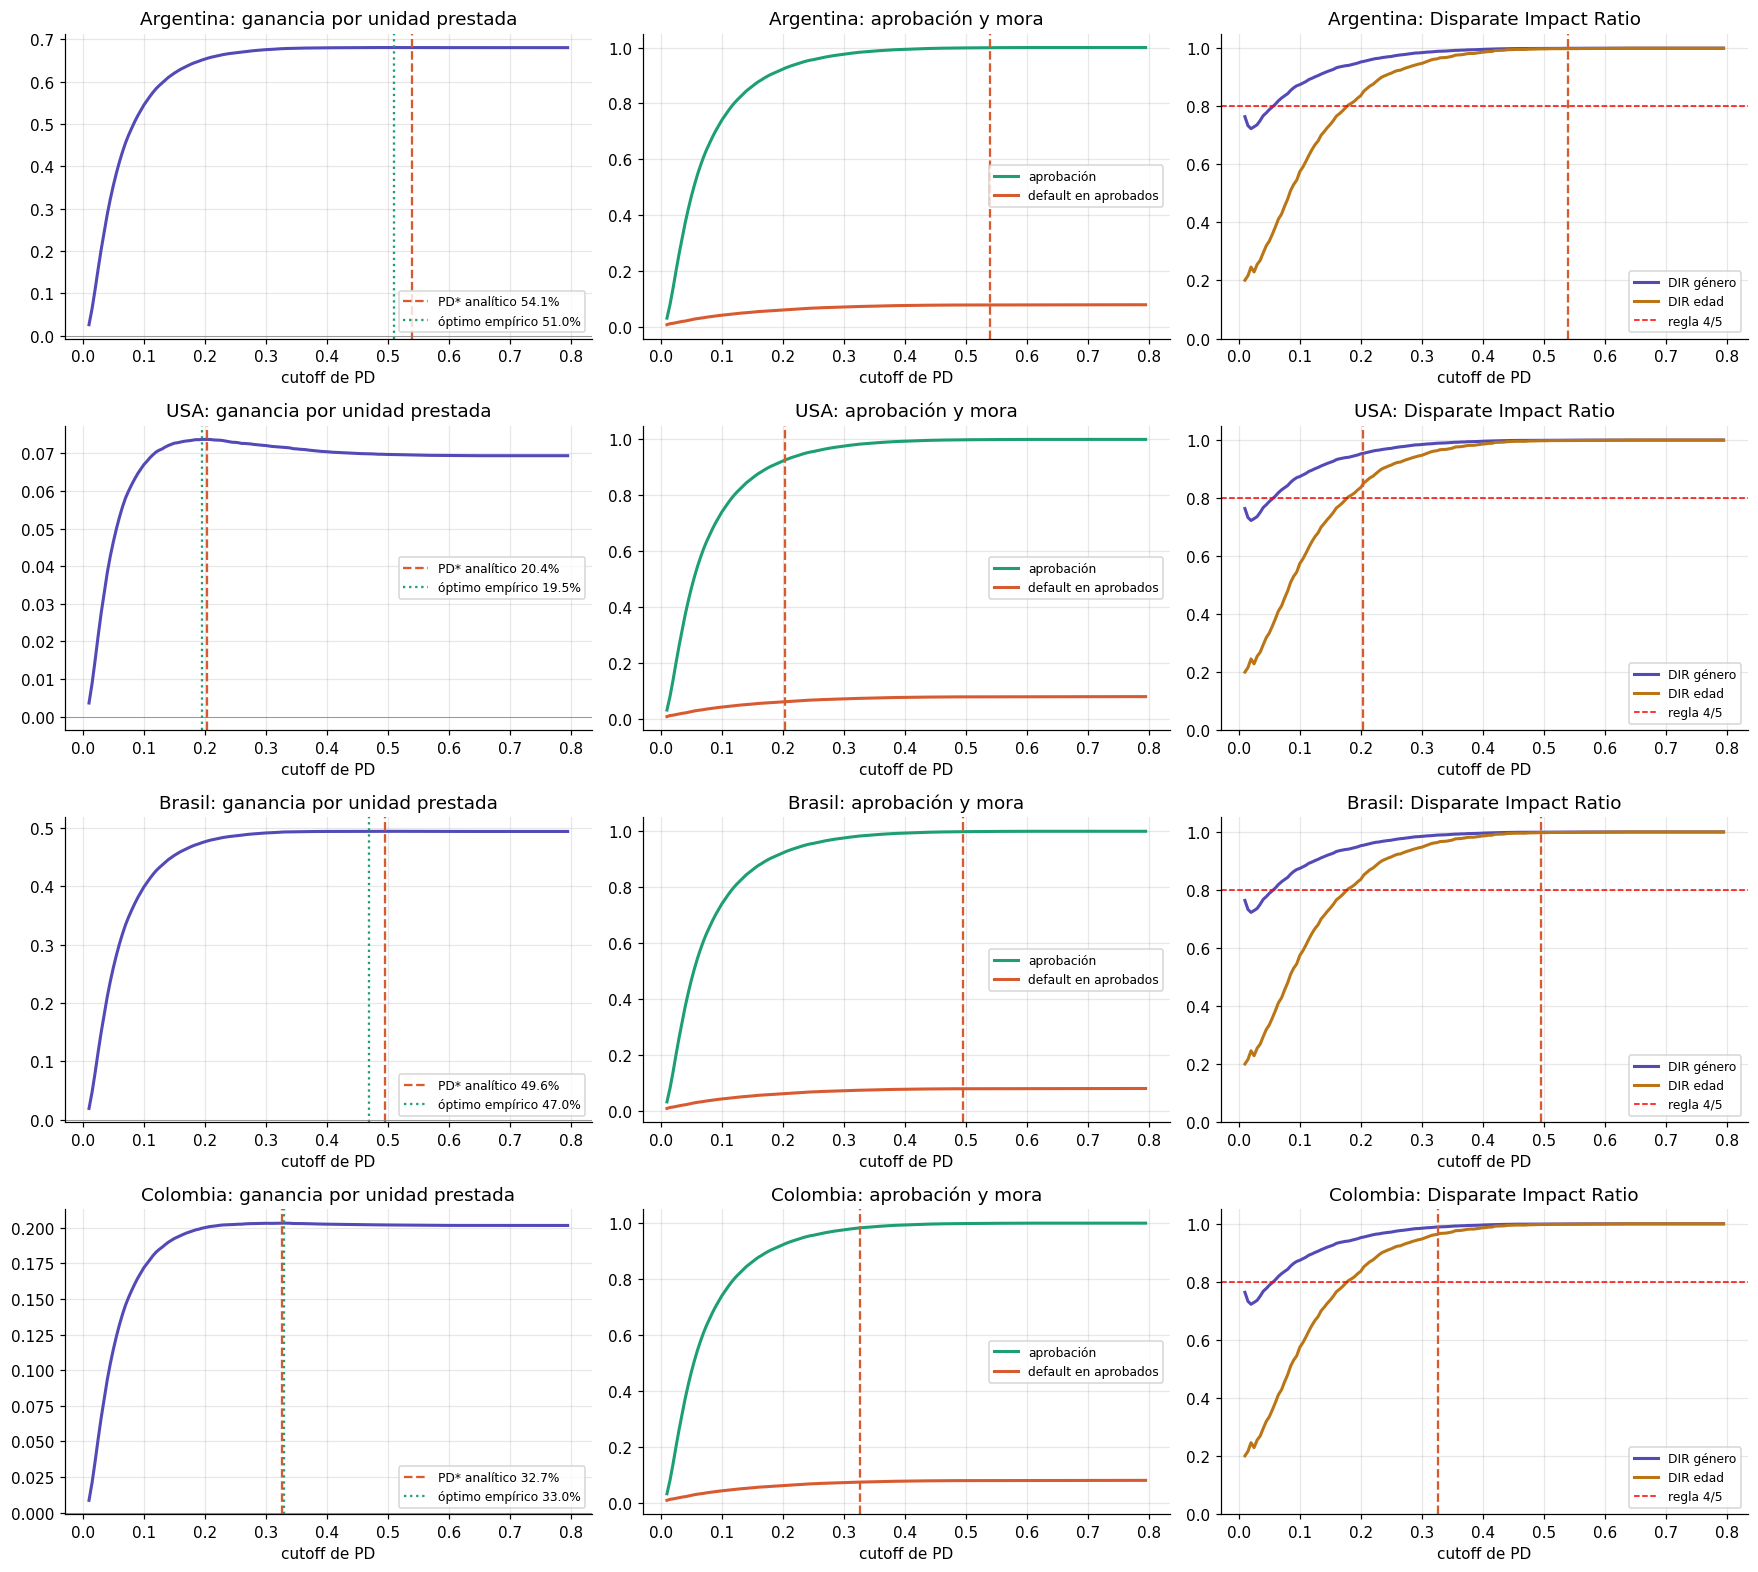

In [4]:
fig, axes = plt.subplots(len(curvas), 3, figsize=(16, 3.6 * len(curvas)))
for i, (m, df) in enumerate(curvas.items()):
    pstar = mercados.loc[m, 'pd_breakeven']
    emp   = df.loc[df['ganancia'].idxmax(), 'cutoff']
    ax = axes[i, 0]
    ax.plot(df['cutoff'], df['ganancia'], color='#534AB7', lw=2)
    ax.axvline(pstar, color='#D85A30', ls='--', label=f'PD* analítico {pstar:.1%}')
    ax.axvline(emp, color='#1D9E75', ls=':', label=f'óptimo empírico {emp:.1%}')
    ax.axhline(0, color='gray', lw=0.5)
    ax.set_title(f'{m}: ganancia por unidad prestada'); ax.legend(fontsize=8)
    axes[i, 1].plot(df['cutoff'], df['aprobacion'], color='#1D9E75', lw=2, label='aprobación')
    axes[i, 1].plot(df['cutoff'], df['mora_aprobados'], color='#D85A30', lw=2, label='default en aprobados')
    axes[i, 1].axvline(pstar, color='#D85A30', ls='--'); axes[i, 1].legend(fontsize=8)
    axes[i, 1].set_title(f'{m}: aprobación y mora')
    axes[i, 2].plot(df['cutoff'], df['dir_genero'], color='#534AB7', lw=2, label='DIR género')
    axes[i, 2].plot(df['cutoff'], df['dir_edad'], color='#BA7517', lw=2, label='DIR edad')
    axes[i, 2].axhline(0.80, color='red', ls='--', lw=1, label='regla 4/5')
    axes[i, 2].axvline(pstar, color='#D85A30', ls='--')
    axes[i, 2].set_ylim(0, 1.05); axes[i, 2].legend(fontsize=8)
    axes[i, 2].set_title(f'{m}: Disparate Impact Ratio')
    for ax in axes[i]:
        ax.set_xlabel('cutoff de PD'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('reports/figures/threshold_analysis_by_market.png', dpi=150, bbox_inches='tight')
plt.show()

## 2.3 Comparativa por mercado y costo del fairness

El **costo del fairness** es la ganancia que se resigna al exigir DIR ≥ 0,80.

In [5]:
filas = []
for m, df in curvas.items():
    pstar = mercados.loc[m, 'pd_breakeven']
    at = df.iloc[(df['cutoff'] - pstar).abs().argmin()]
    opt = df.loc[df['ganancia'].idxmax()]
    fila = {
        'mercado': m, 'PD*': pstar, 'óptimo empírico': opt['cutoff'],
        'aprobación en PD*': at['aprobacion'], 'mora aprobados': at['mora_aprobados'],
        'ganancia en PD*': at['ganancia'], 'DIR género': at['dir_genero'], 'DIR edad': at['dir_edad'],
    }
    for attr in ['genero', 'edad']:
        ok = df[df[f'dir_{attr}'] >= 0.80]
        if len(ok):
            best = ok.loc[ok['ganancia'].idxmax()]
            fila[f'cutoff justo ({attr})'] = best['cutoff']
            fila[f'costo fairness {attr} (%)'] = 1 - best['ganancia'] / opt['ganancia']
        else:
            fila[f'cutoff justo ({attr})'] = np.nan
            fila[f'costo fairness {attr} (%)'] = np.nan
    filas.append(fila)

comp = pd.DataFrame(filas).set_index('mercado')
comp.style.format({c: '{:.1%}' for c in comp.columns if c not in ('ganancia en PD*', 'DIR género', 'DIR edad')}
                  | {'ganancia en PD*': '{:.4f}', 'DIR género': '{:.3f}', 'DIR edad': '{:.3f}'})

,PD*,óptimo empírico,aprobación en PD*,mora aprobados,ganancia en PD*,DIR género,DIR edad,cutoff justo (genero),costo fairness genero (%),cutoff justo (edad),costo fairness edad (%)
mercado,,,,,,,,,,,
Argentina,54.1%,51.0%,99.9%,8.0%,0.6807,0.999,0.998,51.0%,0.0%,51.0%,0.0%
USA,20.4%,19.5%,92.8%,6.3%,0.0737,0.955,0.852,19.5%,0.0%,19.5%,0.0%
Brasil,49.6%,47.0%,99.9%,8.0%,0.4942,0.999,0.998,47.0%,0.0%,47.0%,0.0%
Colombia,32.7%,33.0%,98.3%,7.4%,0.2032,0.989,0.963,33.0%,0.0%,33.0%,0.0%


In [6]:
# Contraste: qué pasa si se usa el score SIN calibrar como si fuera PD
r, lgd = mercados.loc['USA', ['tasa_interes_anual', 'lgd']]
crudo = curva(raw_score, r, lgd)
pstar = breakeven_pd(r, lgd)
at_raw = crudo.iloc[(crudo['cutoff'] - pstar).abs().argmin()]
at_cal = curvas['USA'].iloc[(curvas['USA']['cutoff'] - pstar).abs().argmin()]
print(f'USA, cutoff PD* = {pstar:.1%}')
print(f'  con score crudo  -> aprobación {at_raw["aprobacion"]:.1%} | ganancia {at_raw["ganancia"]:.4f}')
print(f'  con PD calibrada -> aprobación {at_cal["aprobacion"]:.1%} | ganancia {at_cal["ganancia"]:.4f}')

USA, cutoff PD* = 20.4%
  con score crudo  -> aprobación 22.7% | ganancia 0.0238
  con PD calibrada -> aprobación 92.8% | ganancia 0.0737


## 2.4 Conclusiones

**1. El cutoff analítico funciona porque la PD está calibrada.**

| Mercado | PD\* analítico | Óptimo empírico |
|---|---:|---:|
| USA | 20,4% | 19,5% |
| Colombia | 32,7% | 33,0% |
| Brasil | 49,6% | 47,0% |
| Argentina | 54,1% | 51,0% |

Las diferencias están dentro de la resolución de la grilla. La regla `PD* = r/(r+LGD)` es
transparente y fácil de defender ante un comité de crédito.

**2. Usar el score sin calibrar destruye valor.** En USA, aplicar el cutoff de 20,4% sobre el
score crudo aprueba sólo al 22,7% de las solicitudes. La ganancia por unidad cae de 0,074 a
0,024, un tercio. Ese es el costo concreto de no calibrar.

**3. Con TEAs nominales altas, el modelo casi no rechaza.** En Argentina (80%) y Brasil (59%)
la aprobación en PD\* es 99,9%. Esto no significa que convenga prestarle a todos: la TEA
nominal no descuenta inflación, costo de fondeo ni costos operativos. Con el margen *real* el
cutoff sería mucho más bajo. Es la principal limitación de este ejercicio, y el próximo paso
sería modelar el margen neto.

**4. Fairness: el DIR no es la restricción activa.**
- En el cutoff de USA, el DIR es 0,955 por género y 0,852 por edad. Los dos superan la regla
  de los 4/5, y exigir DIR ≥ 0,80 no tiene costo en ganancia en ningún mercado.
- Los flags de fairness del pipeline vienen de otras métricas: diferencia de aprobación entre
  <25 y >55 de 15 pp, y una brecha de TPR por edad. Ver `reports/fairness_report.json` y la
  notebook 03.

**Decisión:** el pipeline usa USA como mercado de referencia (cutoff 20,35%), porque es el
supuesto más conservador y el único con una tasa cercana a un margen real.